In [ ]:
# CELL 1 — MOUNT GOOGLE DRIVE


from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Main project directory
PROJECT_ROOT = "/content/drive/MyDrive/LungSegmentation"

# ResUNet experiment directory
RESUNET_ROOT = os.path.join(PROJECT_ROOT, "ResUNet")

print("=" * 60)
print("Google Drive mounted successfully.")
print("=" * 60)

print(f"Project root : {PROJECT_ROOT}")
print(f"ResUNet root : {RESUNET_ROOT}")

# Verify that Google Drive is accessible
assert os.path.exists("/content/drive/MyDrive"), \
    "Google Drive was not mounted correctly."

print("\nDrive verification: PASSED")

Mounted at /content/drive
Google Drive mounted successfully.
Project root : /content/drive/MyDrive/LungSegmentation
ResUNet root : /content/drive/MyDrive/LungSegmentation/ResUNet

Drive verification: PASSED


In [ ]:
# CELL 2 — Create / Check ResUNet Project Directories


from pathlib import Path

# Persistent project root on Google Drive
PROJECT_ROOT = Path("/content/drive/MyDrive/LungSegmentation")

# ResUNet-specific root directory
RESUNET_ROOT = PROJECT_ROOT / "ResUNet"

# ResUNet subdirectories
RESUNET_DIRS = {
    "checkpoints": RESUNET_ROOT / "checkpoints",
    "models": RESUNET_ROOT / "models",
    "history": RESUNET_ROOT / "history",
    "results": RESUNET_ROOT / "results",
    "predictions": RESUNET_ROOT / "predictions",
    "visualizations": RESUNET_ROOT / "visualizations",
    "config": RESUNET_ROOT / "config",
    "splits": RESUNET_ROOT / "splits",
}

# Create directories without deleting existing files
for directory in RESUNET_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

# Display the structure
print("=" * 60)
print("ResUNet project directories")
print("=" * 60)

print(f"\nProject root:")
print(PROJECT_ROOT)

print(f"\nResUNet root:")
print(RESUNET_ROOT)

print("\nCreated / verified directories:")

for name, directory in RESUNET_DIRS.items():
    print(f"  ✓ {name:<15} → {directory}")

print("\nDirectory setup completed successfully.")

ResUNet project directories

Project root:
/content/drive/MyDrive/LungSegmentation

ResUNet root:
/content/drive/MyDrive/LungSegmentation/ResUNet

Created / verified directories:
  ✓ checkpoints     → /content/drive/MyDrive/LungSegmentation/ResUNet/checkpoints
  ✓ models          → /content/drive/MyDrive/LungSegmentation/ResUNet/models
  ✓ history         → /content/drive/MyDrive/LungSegmentation/ResUNet/history
  ✓ results         → /content/drive/MyDrive/LungSegmentation/ResUNet/results
  ✓ predictions     → /content/drive/MyDrive/LungSegmentation/ResUNet/predictions
  ✓ visualizations  → /content/drive/MyDrive/LungSegmentation/ResUNet/visualizations
  ✓ config          → /content/drive/MyDrive/LungSegmentation/ResUNet/config
  ✓ splits          → /content/drive/MyDrive/LungSegmentation/ResUNet/splits

Directory setup completed successfully.


In [ ]:
# CELL 3 — Check / Download Montgomery Dataset


from pathlib import Path
import os

DATASET_ROOT = PROJECT_ROOT / "dataset"
MONTGOMERY_ROOT = DATASET_ROOT / "MontgomerySet"

MONTGOMERY_IMAGE_DIR = MONTGOMERY_ROOT / "CXR_png"
MONTGOMERY_LEFT_MASK_DIR = MONTGOMERY_ROOT / "ManualMask" / "leftMask"
MONTGOMERY_RIGHT_MASK_DIR = MONTGOMERY_ROOT / "ManualMask" / "rightMask"

# Create dataset directory
DATASET_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("Checking Montgomery dataset")
print("=" * 70)

print(f"\nDataset root:")
print(DATASET_ROOT)

print(f"\nMontgomery image directory:")
print(MONTGOMERY_IMAGE_DIR)

print(f"\nLeft-mask directory:")
print(MONTGOMERY_LEFT_MASK_DIR)

print(f"\nRight-mask directory:")
print(MONTGOMERY_RIGHT_MASK_DIR)



# Check whether the required dataset structure already exists


dataset_exists = (
    MONTGOMERY_IMAGE_DIR.exists()
    and MONTGOMERY_LEFT_MASK_DIR.exists()
    and MONTGOMERY_RIGHT_MASK_DIR.exists()
)

if dataset_exists:

    image_count = len(list(MONTGOMERY_IMAGE_DIR.glob("*")))
    left_count = len(list(MONTGOMERY_LEFT_MASK_DIR.glob("*")))
    right_count = len(list(MONTGOMERY_RIGHT_MASK_DIR.glob("*")))

    print("\n✓ Montgomery dataset already exists.")
    print(f"  Images      : {image_count}")
    print(f"  Left masks  : {left_count}")
    print(f"  Right masks : {right_count}")
    print("\nNo download performed.")

else:

    print("\nDataset not found.")
    print("Downloading MontgomerySet from Hugging Face...")

    !pip -q install huggingface_hub

    from huggingface_hub import snapshot_download

    snapshot_download(
        repo_id="Famatsu123/montgomery-shenzhen-tuberculosis-cxr",
        repo_type="dataset",
        local_dir=str(DATASET_ROOT),
        allow_patterns=[
            "MontgomerySet/**"
        ]
    )

    print("\n✓ Montgomery dataset download completed.")

    image_count = len(list(MONTGOMERY_IMAGE_DIR.glob("*")))
    left_count = len(list(MONTGOMERY_LEFT_MASK_DIR.glob("*")))
    right_count = len(list(MONTGOMERY_RIGHT_MASK_DIR.glob("*")))

    print(f"\nImages      : {image_count}")
    print(f"Left masks  : {left_count}")
    print(f"Right masks : {right_count}")

Checking Montgomery dataset

Dataset root:
/content/drive/MyDrive/LungSegmentation/dataset

Montgomery image directory:
/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/CXR_png

Left-mask directory:
/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/ManualMask/leftMask

Right-mask directory:
/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/ManualMask/rightMask

✓ Montgomery dataset already exists.
  Images      : 139
  Left masks  : 139
  Right masks : 138

No download performed.


In [ ]:
# CELL 4 — Imports and Device Configuration


import os
import json
import random
import time
import copy
import csv

from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

print("=" * 70)
print("Environment")
print("=" * 70)

print(f"PyTorch version : {torch.__version__}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device          : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: CUDA GPU is not available.")

Environment
PyTorch version : 2.11.0+cu128
Device          : cuda
GPU             : Tesla T4


In [ ]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

CUDA available: True
GPU: Tesla T4
CUDA version: 12.8


In [ ]:
# ============================================================
# CELL 5 — Verify Montgomery Dataset
# ============================================================

print("=" * 70)
print("Montgomery Dataset Verification")
print("=" * 70)

image_files = sorted(
    [
        p for p in MONTGOMERY_IMAGE_DIR.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]
)

left_mask_files = sorted(
    [
        p for p in MONTGOMERY_LEFT_MASK_DIR.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]
)

right_mask_files = sorted(
    [
        p for p in MONTGOMERY_RIGHT_MASK_DIR.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    ]
)

print(f"\nNumber of X-ray images : {len(image_files)}")
print(f"Number of left masks  : {len(left_mask_files)}")
print(f"Number of right masks : {len(right_mask_files)}")

assert len(image_files) == 138, \
    f"Expected 138 Montgomery images, found {len(image_files)}"

assert len(left_mask_files) == 138, \
    f"Expected 138 left masks, found {len(left_mask_files)}"

assert len(right_mask_files) == 138, \
    f"Expected 138 right masks, found {len(right_mask_files)}"

print("\n✓ Exactly 138 Montgomery images found.")
print("✓ Exactly 138 left masks found.")
print("✓ Exactly 138 right masks found.")

Montgomery Dataset Verification

Number of X-ray images : 138
Number of left masks  : 138
Number of right masks : 138

✓ Exactly 138 Montgomery images found.
✓ Exactly 138 left masks found.
✓ Exactly 138 right masks found.


In [ ]:
# ============================================================
# CELL 6 — Build Image / Left Mask / Right Mask Pairs
# ============================================================

def normalize_stem(path):
    """
    Return filename stem used for matching.
    """
    return path.stem.lower()


image_map = {
    normalize_stem(p): p
    for p in image_files
}

left_mask_map = {
    normalize_stem(p): p
    for p in left_mask_files
}

right_mask_map = {
    normalize_stem(p): p
    for p in right_mask_files
}


records = []

for image_stem, image_path in image_map.items():

    if image_stem not in left_mask_map:
        continue

    if image_stem not in right_mask_map:
        continue

    records.append({
        "id": image_stem,
        "image": str(image_path),
        "left_mask": str(left_mask_map[image_stem]),
        "right_mask": str(right_mask_map[image_stem])
    })


print("=" * 70)
print("Image / Mask Pair Verification")
print("=" * 70)

print(f"\nValid image-mask pairs: {len(records)}")

assert len(records) == 138, \
    f"Expected 138 valid pairs, found {len(records)}"

print("✓ All 138 images have corresponding left and right masks.")

print("\nFirst 5 records:")

for record in records[:5]:
    print(record)

Image / Mask Pair Verification

Valid image-mask pairs: 138
✓ All 138 images have corresponding left and right masks.

First 5 records:
{'id': 'mcucxr_0001_0', 'image': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/CXR_png/MCUCXR_0001_0.png', 'left_mask': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/ManualMask/leftMask/MCUCXR_0001_0.png', 'right_mask': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/ManualMask/rightMask/MCUCXR_0001_0.png'}
{'id': 'mcucxr_0002_0', 'image': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/CXR_png/MCUCXR_0002_0.png', 'left_mask': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/ManualMask/leftMask/MCUCXR_0002_0.png', 'right_mask': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/ManualMask/rightMask/MCUCXR_0002_0.png'}
{'id': 'mcucxr_0003_0', 'image': '/content/drive/MyDrive/LungSegmentation/dataset/MontgomerySet/CXR_png/MCUCXR_0003_0.png', 'left_mask': '/content/d

In [ ]:
# ============================================================
# CELL 7 — Montgomery Lung Segmentation Dataset
# ============================================================

IMAGE_SIZE = 512


class MontgomeryLungDataset(Dataset):

    def __init__(self, records):

        self.records = records

    def __len__(self):

        return len(self.records)

    def __getitem__(self, index):

        record = self.records[index]

        # ----------------------------------------------------
        # Load X-ray as RGB
        # ----------------------------------------------------
        image = cv2.imread(
            record["image"],
            cv2.IMREAD_COLOR
        )

        if image is None:
            raise RuntimeError(
                f"Could not read image: {record['image']}"
            )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Resize RGB image
        image = cv2.resize(
            image,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

        # Convert to float
        image = image.astype(np.float32) / 255.0

        # HWC -> CHW
        image = np.transpose(
            image,
            (2, 0, 1)
        )

        # ----------------------------------------------------
        # Load left lung mask
        # ----------------------------------------------------
        left_mask = cv2.imread(
            record["left_mask"],
            cv2.IMREAD_GRAYSCALE
        )

        # ----------------------------------------------------
        # Load right lung mask
        # ----------------------------------------------------
        right_mask = cv2.imread(
            record["right_mask"],
            cv2.IMREAD_GRAYSCALE
        )

        if left_mask is None:
            raise RuntimeError(
                f"Could not read left mask: {record['left_mask']}"
            )

        if right_mask is None:
            raise RuntimeError(
                f"Could not read right mask: {record['right_mask']}"
            )

        # Resize masks using nearest-neighbor
        left_mask = cv2.resize(
            left_mask,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        right_mask = cv2.resize(
            right_mask,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        # ----------------------------------------------------
        # Combine left and right lungs
        # ----------------------------------------------------
        combined_mask = np.maximum(
            left_mask,
            right_mask
        )

        combined_mask = (
            combined_mask > 0
        ).astype(np.float32)

        # Add channel dimension
        combined_mask = np.expand_dims(
            combined_mask,
            axis=0
        )

        # Convert to tensors
        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            combined_mask,
            dtype=torch.float32
        )

        return image, mask

In [ ]:
# ============================================================
# CELL 8 — Create Full Dataset
# ============================================================

full_dataset = MontgomeryLungDataset(records)

print("=" * 70)
print("Full Dataset")
print("=" * 70)

print(f"\nTotal samples: {len(full_dataset)}")

sample_image, sample_mask = full_dataset[0]

print(f"Image shape : {sample_image.shape}")
print(f"Mask shape  : {sample_mask.shape}")

print(f"Image dtype : {sample_image.dtype}")
print(f"Mask dtype  : {sample_mask.dtype}")

print(f"Image range : {sample_image.min().item():.4f} "
      f"to {sample_image.max().item():.4f}")

print(f"Mask values : {torch.unique(sample_mask).tolist()}")

Full Dataset

Total samples: 138
Image shape : torch.Size([3, 512, 512])
Mask shape  : torch.Size([1, 512, 512])
Image dtype : torch.float32
Mask dtype  : torch.float32
Image range : 0.0000 to 1.0000
Mask values : [0.0, 1.0]


In [ ]:
# ============================================================
# CELL 9 — Exact Train / Validation / Test Split
# ============================================================

SPLIT_FILE = RESUNET_DIRS["splits"] / "split_indices_seed42.json"

TOTAL_SIZE = len(full_dataset)

TRAIN_SIZE = int(0.80 * TOTAL_SIZE)
VAL_SIZE = int(0.10 * TOTAL_SIZE)
TEST_SIZE = TOTAL_SIZE - TRAIN_SIZE - VAL_SIZE

print("=" * 70)
print("Dataset Split")
print("=" * 70)

print(f"\nTotal : {TOTAL_SIZE}")
print(f"Train : {TRAIN_SIZE}")
print(f"Val   : {VAL_SIZE}")
print(f"Test  : {TEST_SIZE}")


if SPLIT_FILE.exists():

    print("\n✓ Existing split found.")
    print("Loading saved split indices...")

    with open(SPLIT_FILE, "r") as f:
        split_data = json.load(f)

    train_indices = split_data["train_indices"]
    val_indices = split_data["val_indices"]
    test_indices = split_data["test_indices"]

else:

    print("\nNo saved split found.")
    print("Creating split using random seed 42...")

    generator = torch.Generator().manual_seed(42)

    permutation = torch.randperm(
        TOTAL_SIZE,
        generator=generator
    ).tolist()

    train_indices = permutation[:TRAIN_SIZE]

    val_indices = permutation[
        TRAIN_SIZE:
        TRAIN_SIZE + VAL_SIZE
    ]

    test_indices = permutation[
        TRAIN_SIZE + VAL_SIZE:
    ]

    split_data = {
        "seed": 42,
        "total_size": TOTAL_SIZE,
        "train_size": TRAIN_SIZE,
        "val_size": VAL_SIZE,
        "test_size": TEST_SIZE,
        "train_indices": train_indices,
        "val_indices": val_indices,
        "test_indices": test_indices
    }

    with open(SPLIT_FILE, "w") as f:
        json.dump(
            split_data,
            f,
            indent=4
        )

    print(f"\n✓ Split saved to:")
    print(SPLIT_FILE)


print("\nFinal split:")
print(f"Train: {len(train_indices)}")
print(f"Val  : {len(val_indices)}")
print(f"Test : {len(test_indices)}")

assert len(train_indices) == 110
assert len(val_indices) == 13
assert len(test_indices) == 15

print("\n✓ Exact 110 / 13 / 15 split confirmed.")

Dataset Split

Total : 138
Train : 110
Val   : 13
Test  : 15

✓ Existing split found.
Loading saved split indices...

Final split:
Train: 110
Val  : 13
Test : 15

✓ Exact 110 / 13 / 15 split confirmed.


In [ ]:
# ============================================================
# CELL 10 — Dataset Subsets and DataLoaders
# ============================================================

train_dataset = torch.utils.data.Subset(
    full_dataset,
    train_indices
)

val_dataset = torch.utils.data.Subset(
    full_dataset,
    val_indices
)

test_dataset = torch.utils.data.Subset(
    full_dataset,
    test_indices
)


BATCH_SIZE = 1

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


print("=" * 70)
print("DataLoaders")
print("=" * 70)

print(f"\nTrain samples : {len(train_dataset)}")
print(f"Val samples   : {len(val_dataset)}")
print(f"Test samples  : {len(test_dataset)}")

print(f"\nBatch size    : {BATCH_SIZE}")
print("Train shuffle : True")
print("Val shuffle   : False")
print("Test shuffle  : False")

DataLoaders

Train samples : 110
Val samples   : 13
Test samples  : 15

Batch size    : 1
Train shuffle : True
Val shuffle   : False
Test shuffle  : False


In [ ]:
# ============================================================
# CELL 11 — Verify DataLoader Batch
# ============================================================

images, masks = next(iter(train_loader))

print("=" * 70)
print("Batch Verification")
print("=" * 70)

print(f"\nImages shape : {images.shape}")
print(f"Masks shape  : {masks.shape}")

print(f"Images dtype : {images.dtype}")
print(f"Masks dtype  : {masks.dtype}")

print(f"Images range : {images.min().item():.4f} "
      f"to {images.max().item():.4f}")

print(f"Mask values  : {torch.unique(masks).tolist()}")

assert images.shape == (1, 3, 512, 512)
assert masks.shape == (1, 1, 512, 512)

print("\n✓ Input shape is [1, 3, 512, 512].")
print("✓ Target shape is [1, 1, 512, 512].")

Batch Verification

Images shape : torch.Size([1, 3, 512, 512])
Masks shape  : torch.Size([1, 1, 512, 512])
Images dtype : torch.float32
Masks dtype  : torch.float32
Images range : 0.0000 to 1.0000
Mask values  : [0.0, 1.0]

✓ Input shape is [1, 3, 512, 512].
✓ Target shape is [1, 1, 512, 512].


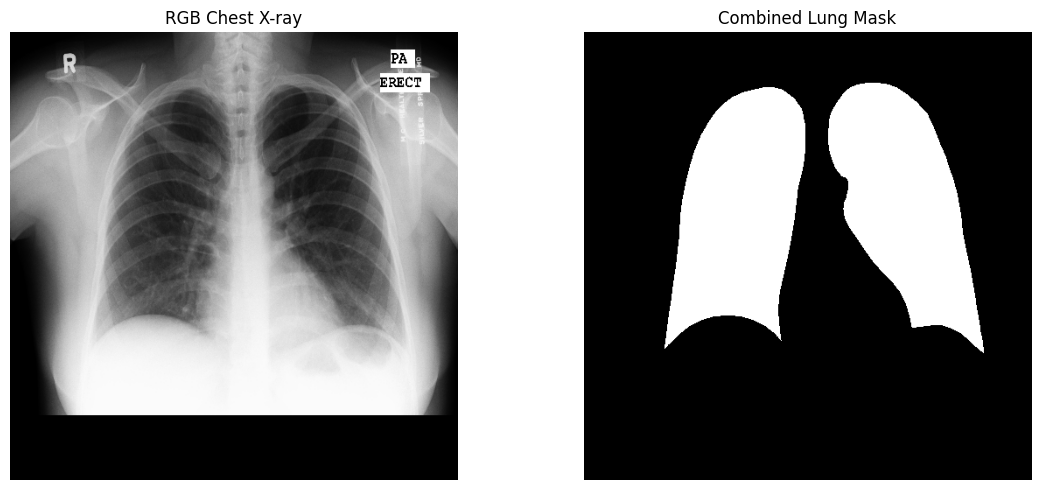

In [ ]:
# ============================================================
# CELL 12 — Visualize X-ray and Combined Lung Mask
# ============================================================

image, mask = full_dataset[0]

image_np = image.permute(1, 2, 0).numpy()
mask_np = mask.squeeze(0).numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_np)
plt.title("RGB Chest X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_np, cmap="gray")
plt.title("Combined Lung Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 13 — Exact ResUNet Building Blocks
# ============================================================

class BNAct(nn.Module):

    def __init__(self, channels, act=True):
        super().__init__()

        self.bn = nn.BatchNorm2d(channels)

        self.act = (
            nn.ReLU(inplace=True)
            if act
            else nn.Identity()
        )

    def forward(self, x):

        x = self.bn(x)
        x = self.act(x)

        return x


class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        filters,
        kernel_size=3,
        stride=1
    ):
        super().__init__()

        self.bn_act = BNAct(
            in_channels,
            act=True
        )

        self.conv = nn.Conv2d(
            in_channels,
            filters,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            stride=stride,
            bias=True
        )

    def forward(self, x):

        x = self.bn_act(x)
        x = self.conv(x)

        return x


class Stem(nn.Module):

    def __init__(
        self,
        in_channels,
        filters,
        kernel_size=3,
        stride=1
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            filters,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            stride=stride
        )

        self.conv_block = ConvBlock(
            filters,
            filters,
            kernel_size=kernel_size,
            stride=stride
        )

        self.shortcut = nn.Conv2d(
            in_channels,
            filters,
            kernel_size=1,
            padding=0,
            stride=stride
        )

        self.shortcut_bn = BNAct(
            filters,
            act=False
        )

    def forward(self, x):

        conv = self.conv(x)

        conv = self.conv_block(conv)

        shortcut = self.shortcut(x)

        shortcut = self.shortcut_bn(shortcut)

        output = conv + shortcut

        return output


class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        filters,
        kernel_size=3,
        stride=1
    ):
        super().__init__()

        self.conv1 = ConvBlock(
            in_channels,
            filters,
            kernel_size=kernel_size,
            stride=stride
        )

        self.conv2 = ConvBlock(
            filters,
            filters,
            kernel_size=kernel_size,
            stride=1
        )

        self.shortcut = nn.Conv2d(
            in_channels,
            filters,
            kernel_size=1,
            padding=0,
            stride=stride
        )

        self.shortcut_bn = BNAct(
            filters,
            act=False
        )

    def forward(self, x):

        res = self.conv1(x)

        res = self.conv2(res)

        shortcut = self.shortcut(x)

        shortcut = self.shortcut_bn(shortcut)

        output = shortcut + res

        return output


class UpSampleConcatBlock(nn.Module):

    def forward(self, x, xskip):

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="nearest"
        )

        x = torch.cat(
            [x, xskip],
            dim=1
        )

        return x

In [ ]:
# ============================================================
# CELL 14 — ResUNet Architecture
# ============================================================

class ResUNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):
        super().__init__()

        # Exact filter progression from original implementation
        f = [16, 32, 64, 128, 256]

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        self.e1 = Stem(
            in_channels,
            f[0]
        )

        self.e2 = ResidualBlock(
            f[0],
            f[1],
            stride=2
        )

        self.e3 = ResidualBlock(
            f[1],
            f[2],
            stride=2
        )

        self.e4 = ResidualBlock(
            f[2],
            f[3],
            stride=2
        )

        self.e5 = ResidualBlock(
            f[3],
            f[4],
            stride=2
        )

        # ----------------------------------------------------
        # Bridge
        # ----------------------------------------------------

        self.b0 = ConvBlock(
            f[4],
            f[4],
            stride=1
        )

        self.b1 = ConvBlock(
            f[4],
            f[4],
            stride=1
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.up = UpSampleConcatBlock()

        self.d1 = ResidualBlock(
            f[4] + f[3],
            f[4]
        )

        self.d2 = ResidualBlock(
            f[4] + f[2],
            f[3]
        )

        self.d3 = ResidualBlock(
            f[3] + f[1],
            f[2]
        )

        self.d4 = ResidualBlock(
            f[2] + f[0],
            f[1]
        )

        # ----------------------------------------------------
        # Final 1x1 convolution
        #
        # IMPORTANT:
        # No sigmoid here because we use
        # BCEWithLogitsLoss.
        # ----------------------------------------------------

        self.output = nn.Conv2d(
            f[1],
            out_channels,
            kernel_size=1,
            padding=0
        )

    def forward(self, x):

        # Encoder
        e1 = self.e1(x)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.e4(e3)
        e5 = self.e5(e4)

        # Bridge
        b0 = self.b0(e5)
        b1 = self.b1(b0)

        # Decoder
        u1 = self.up(b1, e4)
        d1 = self.d1(u1)

        u2 = self.up(d1, e3)
        d2 = self.d2(u2)

        u3 = self.up(d2, e2)
        d3 = self.d3(u3)

        u4 = self.up(d3, e1)
        d4 = self.d4(u4)

        # Output logits
        output = self.output(d4)

        return output

In [ ]:
# ============================================================
# CELL 14 — ResUNet Architecture
# ============================================================

class ResUNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):
        super().__init__()

        # Exact filter progression from original implementation
        f = [16, 32, 64, 128, 256]

        # ----------------------------------------------------
        # Encoder
        # ----------------------------------------------------

        self.e1 = Stem(
            in_channels,
            f[0]
        )

        self.e2 = ResidualBlock(
            f[0],
            f[1],
            stride=2
        )

        self.e3 = ResidualBlock(
            f[1],
            f[2],
            stride=2
        )

        self.e4 = ResidualBlock(
            f[2],
            f[3],
            stride=2
        )

        self.e5 = ResidualBlock(
            f[3],
            f[4],
            stride=2
        )

        # ----------------------------------------------------
        # Bridge
        # ----------------------------------------------------

        self.b0 = ConvBlock(
            f[4],
            f[4],
            stride=1
        )

        self.b1 = ConvBlock(
            f[4],
            f[4],
            stride=1
        )

        # ----------------------------------------------------
        # Decoder
        # ----------------------------------------------------

        self.up = UpSampleConcatBlock()

        self.d1 = ResidualBlock(
            f[4] + f[3],
            f[4]
        )

        self.d2 = ResidualBlock(
            f[4] + f[2],
            f[3]
        )

        self.d3 = ResidualBlock(
            f[3] + f[1],
            f[2]
        )

        self.d4 = ResidualBlock(
            f[2] + f[0],
            f[1]
        )

        # ----------------------------------------------------
        # Final 1x1 convolution
        #
        # IMPORTANT:
        # No sigmoid here because we use
        # BCEWithLogitsLoss.
        # ----------------------------------------------------

        self.output = nn.Conv2d(
            f[1],
            out_channels,
            kernel_size=1,
            padding=0
        )

    def forward(self, x):

        # Encoder
        e1 = self.e1(x)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.e4(e3)
        e5 = self.e5(e4)

        # Bridge
        b0 = self.b0(e5)
        b1 = self.b1(b0)

        # Decoder
        u1 = self.up(b1, e4)
        d1 = self.d1(u1)

        u2 = self.up(d1, e3)
        d2 = self.d2(u2)

        u3 = self.up(d2, e2)
        d3 = self.d3(u3)

        u4 = self.up(d3, e1)
        d4 = self.d4(u4)

        # Output logits
        output = self.output(d4)

        return output

In [ ]:
# ============================================================
# CELL 15 — Instantiate ResUNet
# ============================================================

model = ResUNet(
    in_channels=3,
    out_channels=1
).to(DEVICE)


total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print("=" * 70)
print("ResUNet Model")
print("=" * 70)

print(f"\nInput channels : 3")
print(f"Output channels: 1")

print(f"\nTotal parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print("\nModel created successfully.")

ResUNet Model

Input channels : 3
Output channels: 1

Total parameters    : 4,715,761
Trainable parameters: 4,715,761

Model created successfully.


In [ ]:
# ============================================================
# CELL 16 — Model Shape Verification
# ============================================================

model.eval()

with torch.no_grad():

    test_input = torch.randn(
        1,
        3,
        512,
        512,
        device=DEVICE
    )

    test_output = model(test_input)


print("=" * 70)
print("ResUNet Shape Verification")
print("=" * 70)

print(f"\nInput shape : {test_input.shape}")
print(f"Output shape: {test_output.shape}")

assert test_output.shape == (
    1,
    1,
    512,
    512
)

print("\n✓ Output shape is exactly [1, 1, 512, 512].")

ResUNet Shape Verification

Input shape : torch.Size([1, 3, 512, 512])
Output shape: torch.Size([1, 1, 512, 512])

✓ Output shape is exactly [1, 1, 512, 512].


In [ ]:
# ============================================================
# CELL 17 — Loss Functions
# ============================================================

class SoftDiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()

        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.contiguous().view(
            probabilities.size(0),
            -1
        )

        targets = targets.contiguous().view(
            targets.size(0),
            -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        denominator = (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
        )

        dice = (
            2.0 * intersection
            + self.smooth
        ) / (
            denominator
            + self.smooth
        )

        return (1.0 - dice).mean()


class InvSoftDiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()

        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.contiguous().view(
            probabilities.size(0),
            -1
        )

        targets = targets.contiguous().view(
            targets.size(0),
            -1
        )

        intersection = (
            probabilities * targets
        ).sum(dim=1)

        denominator = (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
        )

        dice = (
            2.0 * intersection
            + self.smooth
        ) / (
            denominator
            + self.smooth
        )

        return (
            1.0 / (dice + 1e-7)
        ).mean()


bce_loss_fn = nn.BCEWithLogitsLoss()

dice_loss_fn = SoftDiceLoss()

inv_dice_loss_fn = InvSoftDiceLoss()


def total_loss_function(logits, targets):

    loss_bce = bce_loss_fn(
        logits,
        targets
    )

    loss_dice = dice_loss_fn(
        logits,
        targets
    )

    loss_inv_dice = inv_dice_loss_fn(
        logits,
        targets
    )

    total_loss = (
        loss_bce
        + loss_dice
        + loss_inv_dice
    )

    return (
        total_loss,
        loss_bce,
        loss_dice,
        loss_inv_dice
    )


print("✓ BCEWithLogitsLoss created.")
print("✓ SoftDiceLoss created.")
print("✓ InvSoftDiceLoss created.")
print("✓ Total loss = BCE + SoftDice + InvSoftDice.")

✓ BCEWithLogitsLoss created.
✓ SoftDiceLoss created.
✓ InvSoftDiceLoss created.
✓ Total loss = BCE + SoftDice + InvSoftDice.


In [ ]:
# ============================================================
# CELL 18 — Optimizer
# ============================================================

LEARNING_RATE = 1e-4

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("=" * 70)
print("Optimizer")
print("=" * 70)

print(f"\nOptimizer     : Adam")
print(f"Learning rate : {LEARNING_RATE}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Epochs        : 20")

Optimizer

Optimizer     : Adam
Learning rate : 0.0001
Batch size    : 1
Epochs        : 20


In [ ]:
# ============================================================
# CELL 19 — Checkpoint and Recovery Configuration
# ============================================================

EPOCHS = 20

CHECKPOINT_DIR = RESUNET_DIRS["checkpoints"]

LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_checkpoint.pth"

BEST_CHECKPOINT = CHECKPOINT_DIR / "best_checkpoint.pth"

FINAL_MODEL_PATH = RESUNET_DIRS["models"] / "resunet_final.pth"

HISTORY_PATH = RESUNET_DIRS["history"] / "training_history.json"


history = {
    "train_loss": [],
    "val_loss": [],
    "train_bce": [],
    "train_dice": [],
    "train_inv_dice": [],
    "val_bce": [],
    "val_dice": [],
    "val_inv_dice": []
}


start_epoch = 0
best_val_loss = float("inf")


print("=" * 70)
print("Checkpoint Configuration")
print("=" * 70)

print(f"\nLatest checkpoint:")
print(LATEST_CHECKPOINT)

print(f"\nBest checkpoint:")
print(BEST_CHECKPOINT)

print(f"\nFinal model:")
print(FINAL_MODEL_PATH)

Checkpoint Configuration

Latest checkpoint:
/content/drive/MyDrive/LungSegmentation/ResUNet/checkpoints/latest_checkpoint.pth

Best checkpoint:
/content/drive/MyDrive/LungSegmentation/ResUNet/checkpoints/best_checkpoint.pth

Final model:
/content/drive/MyDrive/LungSegmentation/ResUNet/models/resunet_final.pth


In [ ]:
# ============================================================
# CELL 20 — Checkpoint Recovery
# ============================================================

if LATEST_CHECKPOINT.exists():

    print("=" * 70)
    print("Resuming Existing Experiment")
    print("=" * 70)

    checkpoint = torch.load(
        LATEST_CHECKPOINT,
        map_location=DEVICE
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    start_epoch = checkpoint["epoch"] + 1

    best_val_loss = checkpoint.get(
        "best_val_loss",
        float("inf")
    )

    history = checkpoint.get(
        "history",
        history
    )

    print(
        f"\nResuming from epoch {start_epoch}"
    )

    print(
        f"Best validation loss: {best_val_loss:.6f}"
    )

else:

    print("=" * 70)
    print("Starting a New Experiment")
    print("=" * 70)

    start_epoch = 0

    print("\nNo previous checkpoint found.")

Resuming Existing Experiment

Resuming from epoch 20
Best validation loss: 1.175754


In [ ]:
# ============================================================
# CELL 21 — Training and Validation Functions
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    device
):

    model.train()

    running_total = 0.0
    running_bce = 0.0
    running_dice = 0.0
    running_inv_dice = 0.0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(images)

        (
            total_loss,
            loss_bce,
            loss_dice,
            loss_inv_dice
        ) = total_loss_function(
            logits,
            masks
        )

        total_loss.backward()

        optimizer.step()

        running_total += total_loss.item()
        running_bce += loss_bce.item()
        running_dice += loss_dice.item()
        running_inv_dice += loss_inv_dice.item()

    n = len(loader)

    return (
        running_total / n,
        running_bce / n,
        running_dice / n,
        running_inv_dice / n
    )


@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    device
):

    model.eval()

    running_total = 0.0
    running_bce = 0.0
    running_dice = 0.0
    running_inv_dice = 0.0

    for images, masks in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        masks = masks.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        (
            total_loss,
            loss_bce,
            loss_dice,
            loss_inv_dice
        ) = total_loss_function(
            logits,
            masks
        )

        running_total += total_loss.item()
        running_bce += loss_bce.item()
        running_dice += loss_dice.item()
        running_inv_dice += loss_inv_dice.item()

    n = len(loader)

    return (
        running_total / n,
        running_bce / n,
        running_dice / n,
        running_inv_dice / n
    )

In [ ]:
# ============================================================
# CELL 22 — Train ResUNet
# ============================================================

print("=" * 70)
print("ResUNet Training")
print("=" * 70)

print(f"\nStarting epoch : {start_epoch + 1}")
print(f"Total epochs   : {EPOCHS}")

for epoch in range(
    start_epoch,
    EPOCHS
):

    epoch_start_time = time.time()

    (
        train_total,
        train_bce,
        train_dice,
        train_inv_dice
    ) = train_one_epoch(
        model,
        train_loader,
        optimizer,
        DEVICE
    )

    (
        val_total,
        val_bce,
        val_dice,
        val_inv_dice
    ) = validate_one_epoch(
        model,
        val_loader,
        DEVICE
    )

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history["train_loss"].append(train_total)
    history["val_loss"].append(val_total)

    history["train_bce"].append(train_bce)
    history["train_dice"].append(train_dice)
    history["train_inv_dice"].append(train_inv_dice)

    history["val_bce"].append(val_bce)
    history["val_dice"].append(val_dice)
    history["val_inv_dice"].append(val_inv_dice)

    # --------------------------------------------------------
    # Save latest checkpoint
    # --------------------------------------------------------

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_total,
        "val_loss": val_total,
        "best_val_loss": best_val_loss,
        "history": history
    }

    epoch_checkpoint_path = (
        CHECKPOINT_DIR /
        f"checkpoint_epoch_{epoch + 1:02d}.pth"
    )

    torch.save(
        checkpoint,
        epoch_checkpoint_path
    )

    torch.save(
        checkpoint,
        LATEST_CHECKPOINT
    )

    # --------------------------------------------------------
    # Best model
    # --------------------------------------------------------

    if val_total < best_val_loss:

        best_val_loss = val_total

        checkpoint["best_val_loss"] = best_val_loss

        torch.save(
            checkpoint,
            BEST_CHECKPOINT
        )

        best_message = "  ← BEST"

    else:

        best_message = ""

    elapsed = time.time() - epoch_start_time

    print(
        f"\nEpoch [{epoch + 1:02d}/{EPOCHS}]"
        f" | Train: {train_total:.6f}"
        f" | Val: {val_total:.6f}"
        f" | Time: {elapsed:.1f}s"
        f"{best_message}"
    )

    print(
        f"   BCE={train_bce:.6f}"
        f" | Dice={train_dice:.6f}"
        f" | InvDice={train_inv_dice:.6f}"
    )

print("\n✓ Training loop completed.")

ResUNet Training

Starting epoch : 21
Total epochs   : 20

✓ Training loop completed.


In [ ]:
# ============================================================
# CELL 23 — Save Final Model and Training History
# ============================================================

# Save final model
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epochs_completed": EPOCHS,
        "best_val_loss": best_val_loss,
        "history": history
    },
    FINAL_MODEL_PATH
)


# Save history separately
with open(HISTORY_PATH, "w") as f:

    json.dump(
        history,
        f,
        indent=4
    )


print("=" * 70)
print("Training Artifacts Saved")
print("=" * 70)

print(f"\nFinal model:")
print(FINAL_MODEL_PATH)

print(f"\nBest checkpoint:")
print(BEST_CHECKPOINT)

print(f"\nLatest checkpoint:")
print(LATEST_CHECKPOINT)

print(f"\nHistory:")
print(HISTORY_PATH)

print("\n✓ All training artifacts saved to Google Drive.")

Training Artifacts Saved

Final model:
/content/drive/MyDrive/LungSegmentation/ResUNet/models/resunet_final.pth

Best checkpoint:
/content/drive/MyDrive/LungSegmentation/ResUNet/checkpoints/best_checkpoint.pth

Latest checkpoint:
/content/drive/MyDrive/LungSegmentation/ResUNet/checkpoints/latest_checkpoint.pth

History:
/content/drive/MyDrive/LungSegmentation/ResUNet/history/training_history.json

✓ All training artifacts saved to Google Drive.


In [ ]:
# ============================================================
# CELL 24 — Load Best ResUNet Model
# ============================================================

print("=" * 70)
print("Loading Best ResUNet")
print("=" * 70)

best_checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)

model.eval()

print("\n✓ Best ResUNet checkpoint loaded.")

print(
    f"Best validation loss: "
    f"{best_checkpoint['best_val_loss']:.6f}"
)

Loading Best ResUNet

✓ Best ResUNet checkpoint loaded.
Best validation loss: 1.175754


In [ ]:
# ============================================================
# CELL 25 — Dice and IoU Metrics
# ============================================================

def dice_score(
    prediction,
    target,
    smooth=1e-7
):

    prediction = prediction.float()
    target = target.float()

    prediction = prediction.view(
        prediction.size(0),
        -1
    )

    target = target.view(
        target.size(0),
        -1
    )

    intersection = (
        prediction * target
    ).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        prediction.sum(dim=1)
        + target.sum(dim=1)
        + smooth
    )

    return dice.mean().item()


def iou_score(
    prediction,
    target,
    smooth=1e-7
):

    prediction = prediction.float()
    target = target.float()

    prediction = prediction.view(
        prediction.size(0),
        -1
    )

    target = target.view(
        target.size(0),
        -1
    )

    intersection = (
        prediction * target
    ).sum(dim=1)

    union = (
        prediction
        + target
        - prediction * target
    ).sum(dim=1)

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    return iou.mean().item()


print("✓ Dice and IoU metric functions ready.")

✓ Dice and IoU metric functions ready.


In [ ]:
# ============================================================
# CELL 26 — Test Set Evaluation
# ============================================================

model.eval()

test_dice_scores = []
test_iou_scores = []

print("=" * 70)
print("Test Set Evaluation")
print("=" * 70)

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(images)

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities >= 0.5
        ).float()

        dice = dice_score(
            predictions,
            masks
        )

        iou = iou_score(
            predictions,
            masks
        )

        test_dice_scores.append(dice)
        test_iou_scores.append(iou)


mean_dice = np.mean(
    test_dice_scores
)

mean_iou = np.mean(
    test_iou_scores
)


print(f"\nTest images : {len(test_dataset)}")
print(f"Mean Dice   : {mean_dice:.6f}")
print(f"Mean IoU    : {mean_iou:.6f}")

Test Set Evaluation

Test images : 15
Mean Dice   : 0.967932
Mean IoU    : 0.938673


In [ ]:
# ============================================================
# CELL 27 — Save Per-Image Test Results
# ============================================================

test_results = []

model.eval()

with torch.no_grad():

    for local_index, (images, masks) in enumerate(test_loader):

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = model(images)

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities >= 0.5
        ).float()

        dice = dice_score(
            predictions,
            masks
        )

        iou = iou_score(
            predictions,
            masks
        )

        original_index = test_indices[
            local_index
        ]

        image_id = records[
            original_index
        ]["id"]

        test_results.append({
            "image_id": image_id,
            "dataset_index": original_index,
            "dice": dice,
            "iou": iou
        })


results_df = pd.DataFrame(
    test_results
)

TEST_RESULTS_PATH = (
    RESUNET_DIRS["results"]
    / "test_results_per_image.csv"
)

results_df.to_csv(
    TEST_RESULTS_PATH,
    index=False
)


summary_path = (
    RESUNET_DIRS["results"]
    / "test_summary.json"
)

summary = {
    "test_samples": len(test_dataset),
    "mean_dice": float(mean_dice),
    "mean_iou": float(mean_iou),
    "threshold": 0.5
}

with open(summary_path, "w") as f:

    json.dump(
        summary,
        f,
        indent=4
    )


print("=" * 70)
print("Test Results Saved")
print("=" * 70)

print(f"\nPer-image results:")
print(TEST_RESULTS_PATH)

print(f"\nSummary:")
print(summary_path)

display(results_df)

Test Results Saved

Per-image results:
/content/drive/MyDrive/LungSegmentation/ResUNet/results/test_results_per_image.csv

Summary:
/content/drive/MyDrive/LungSegmentation/ResUNet/results/test_summary.json


,image_id,dataset_index,dice,iou
0,mcucxr_0083_0,62,0.977137,0.955296
1,mcucxr_0213_1,100,0.968847,0.939577
2,mcucxr_0051_0,36,0.986994,0.974322
3,mcucxr_0023_0,16,0.975842,0.952824
4,mcucxr_0022_0,15,0.963753,0.930042
5,mcucxr_0399_1,137,0.894392,0.808960
6,mcucxr_0028_0,20,0.982767,0.966118
7,mcucxr_0001_0,0,0.979525,0.959872
8,mcucxr_0080_0,59,0.955080,0.914022
9,mcucxr_0042_0,28,0.969828,0.941423


In [ ]:
# ============================================================
# CELL 28 — Save Test Predictions
# ============================================================

PREDICTION_DIR = (
    RESUNET_DIRS["predictions"]
)

PREDICTION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model.eval()

with torch.no_grad():

    for local_index, (images, masks) in enumerate(test_loader):

        images = images.to(DEVICE)

        logits = model(images)

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities >= 0.5
        ).float()

        original_index = test_indices[
            local_index
        ]

        image_id = records[
            original_index
        ]["id"]

        prediction_np = (
            predictions[0, 0]
            .cpu()
            .numpy()
            .astype(np.uint8)
            * 255
        )

        output_path = (
            PREDICTION_DIR
            / f"{image_id}_prediction.png"
        )

        cv2.imwrite(
            str(output_path),
            prediction_np
        )


print("=" * 70)
print("Predictions Saved")
print("=" * 70)

print(f"\nPrediction directory:")
print(PREDICTION_DIR)

Predictions Saved

Prediction directory:
/content/drive/MyDrive/LungSegmentation/ResUNet/predictions


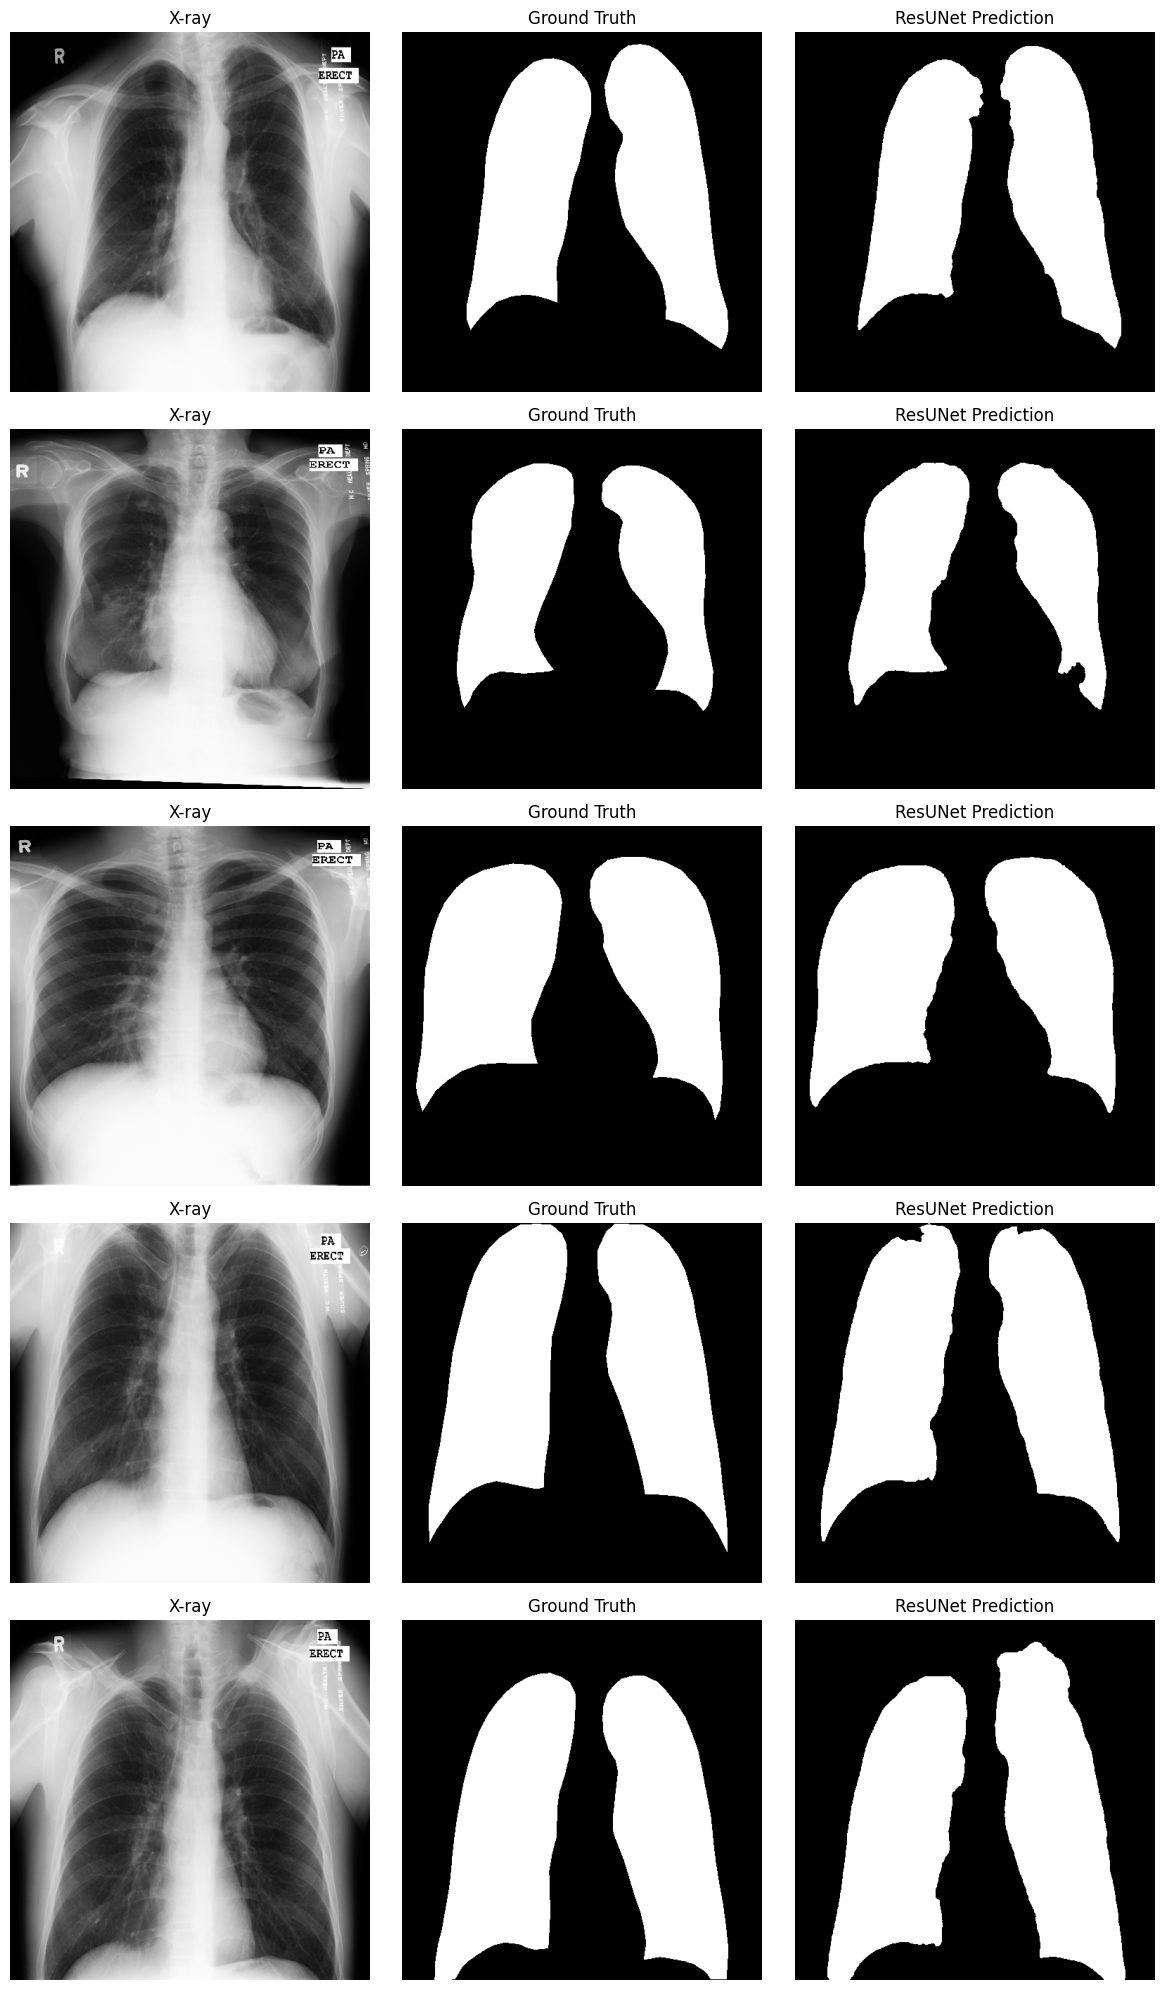


✓ Visualization saved to:
/content/drive/MyDrive/LungSegmentation/ResUNet/visualizations/test_predictions_overview.png


In [ ]:
# ============================================================
# CELL 29 — Visualize Test Predictions
# ============================================================

model.eval()

num_samples_to_show = min(
    5,
    len(test_dataset)
)

fig, axes = plt.subplots(
    num_samples_to_show,
    3,
    figsize=(12, 4 * num_samples_to_show)
)

if num_samples_to_show == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )


with torch.no_grad():

    for row in range(num_samples_to_show):

        image, mask = test_dataset[row]

        input_tensor = (
            image.unsqueeze(0)
            .to(DEVICE)
        )

        logits = model(
            input_tensor
        )

        probability = torch.sigmoid(
            logits
        )

        prediction = (
            probability >= 0.5
        ).float()

        image_np = (
            image
            .permute(1, 2, 0)
            .numpy()
        )

        mask_np = (
            mask
            .squeeze(0)
            .numpy()
        )

        prediction_np = (
            prediction[0, 0]
            .cpu()
            .numpy()
        )

        axes[row, 0].imshow(
            image_np
        )

        axes[row, 0].set_title(
            "X-ray"
        )

        axes[row, 1].imshow(
            mask_np,
            cmap="gray"
        )

        axes[row, 1].set_title(
            "Ground Truth"
        )

        axes[row, 2].imshow(
            prediction_np,
            cmap="gray"
        )

        axes[row, 2].set_title(
            "ResUNet Prediction"
        )

        for col in range(3):
            axes[row, col].axis("off")


plt.tight_layout()

visualization_path = (
    RESUNET_DIRS["visualizations"]
    / "test_predictions_overview.png"
)

plt.savefig(
    visualization_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n✓ Visualization saved to:\n"
    f"{visualization_path}"
)

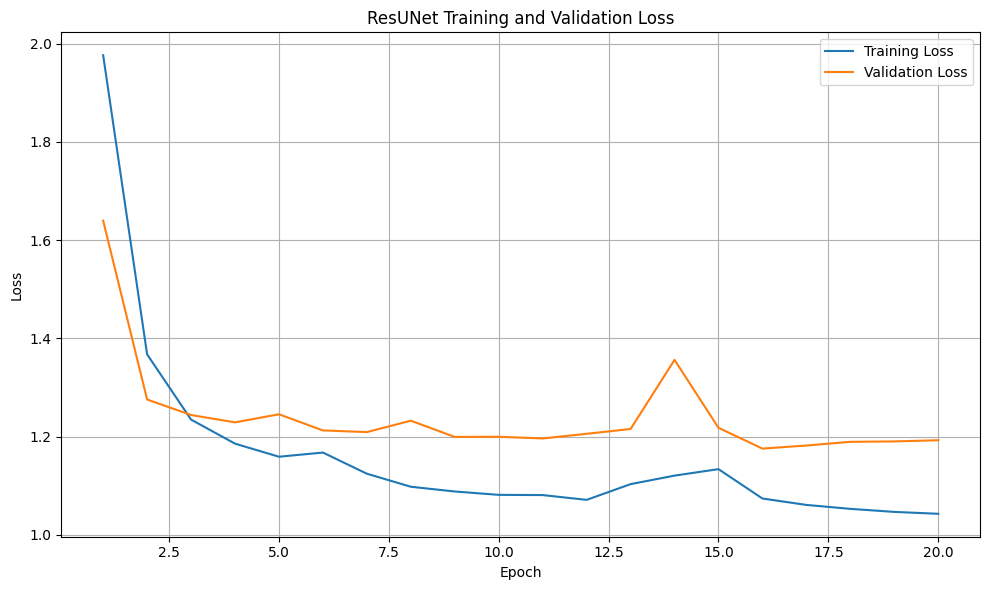


✓ Training history saved to:
/content/drive/MyDrive/LungSegmentation/ResUNet/history/training_validation_loss.png


In [ ]:
# ============================================================
# CELL 30 — Training History
# ============================================================

epochs_completed = len(
    history["train_loss"]
)

epoch_numbers = range(
    1,
    epochs_completed + 1
)


plt.figure(figsize=(10, 6))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epoch_numbers,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResUNet Training and Validation Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

history_plot_path = (
    RESUNET_DIRS["history"]
    / "training_validation_loss.png"
)

plt.savefig(
    history_plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"\n✓ Training history saved to:\n"
    f"{history_plot_path}"
)

In [ ]:
# ============================================================
# CELL 31 — Save Experiment Configuration
# ============================================================

config = {

    "model": "ResUNet",

    "source_repository":
        "https://github.com/mhmodir/Chest-X-Ray-Image_Segmentation_ResUNet",

    "source_notebook":
        "main/Chest_Xray_resunet.ipynb",

    "framework":
        "PyTorch",

    "dataset":
        "Famatsu123/montgomery-shenzhen-tuberculosis-cxr",

    "dataset_subset":
        "MontgomerySet",

    "total_images":
        138,

    "image_channels":
        3,

    "image_size":
        [512, 512],

    "mask_channels":
        1,

    "train_size":
        110,

    "validation_size":
        13,

    "test_size":
        15,

    "split_seed":
        42,

    "batch_size":
        1,

    "epochs":
        20,

    "optimizer":
        "Adam",

    "learning_rate":
        1e-4,

    "loss":
        [
            "BCEWithLogitsLoss",
            "SoftDiceLoss",
            "InvSoftDiceLoss"
        ],

    "prediction_threshold":
        0.5,

    "filters":
        [16, 32, 64, 128, 256],

    "final_activation":
        "logits during training; sigmoid for probability",

    "mean_test_dice":
        float(mean_dice),

    "mean_test_iou":
        float(mean_iou)
}


CONFIG_PATH = (
    RESUNET_DIRS["config"]
    / "resunet_experiment_config.json"
)

with open(CONFIG_PATH, "w") as f:

    json.dump(
        config,
        f,
        indent=4
    )


print("=" * 70)
print("Experiment Configuration Saved")
print("=" * 70)

print(f"\n{CONFIG_PATH}")

Experiment Configuration Saved

/content/drive/MyDrive/LungSegmentation/ResUNet/config/resunet_experiment_config.json


In [ ]:
# ============================================================
# CELL 32 — Final Experiment Summary
# ============================================================

print("\n")
print("=" * 75)
print("                 RESUNET EXPERIMENT SUMMARY")
print("=" * 75)

print("\nMODEL")
print("-" * 75)
print("Architecture : ResUNet")
print("Framework    : PyTorch")
print("Filters      : [16, 32, 64, 128, 256]")
print("Input        : 3 × 512 × 512")
print("Output       : 1 × 512 × 512")

print("\nDATASET")
print("-" * 75)
print("Dataset      : Montgomery")
print("Total        : 138")
print("Train        : 110")
print("Validation   : 13")
print("Test         : 15")
print("Split seed   : 42")

print("\nTRAINING")
print("-" * 75)
print("Epochs       :", EPOCHS)
print("Batch size   :", BATCH_SIZE)
print("Optimizer    : Adam")
print("Learning rate:", LEARNING_RATE)

print("\nLOSS")
print("-" * 75)
print("BCEWithLogitsLoss")
print("SoftDiceLoss")
print("InvSoftDiceLoss")

print("\nEVALUATION")
print("-" * 75)
print(f"Threshold    : 0.5")
print(f"Mean Dice    : {mean_dice:.6f}")
print(f"Mean IoU     : {mean_iou:.6f}")

print("\nSTORAGE")
print("-" * 75)
print(f"Project root : {PROJECT_ROOT}")
print(f"ResUNet root : {RESUNET_ROOT}")

print("\n" + "=" * 75)
print("                 EXPERIMENT COMPLETED")
print("=" * 75)



                 RESUNET EXPERIMENT SUMMARY

MODEL
---------------------------------------------------------------------------
Architecture : ResUNet
Framework    : PyTorch
Filters      : [16, 32, 64, 128, 256]
Input        : 3 × 512 × 512
Output       : 1 × 512 × 512

DATASET
---------------------------------------------------------------------------
Dataset      : Montgomery
Total        : 138
Train        : 110
Validation   : 13
Test         : 15
Split seed   : 42

TRAINING
---------------------------------------------------------------------------
Epochs       : 20
Batch size   : 1
Optimizer    : Adam
Learning rate: 0.0001

LOSS
---------------------------------------------------------------------------
BCEWithLogitsLoss
SoftDiceLoss
InvSoftDiceLoss

EVALUATION
---------------------------------------------------------------------------
Threshold    : 0.5
Mean Dice    : 0.967932
Mean IoU     : 0.938673

STORAGE
----------------------------------------------------------------------

In [ ]:
# ============================================================
# CELL 1 — RESUNET TEST CONFUSION MATRIX
# ============================================================

model.eval()

TP = 0
TN = 0
FP = 0
FN = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        # Model prediction
        logits = model(images)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(logits)

        # Convert probabilities to binary prediction
        predictions = (probabilities >= 0.5).float()

        # Flatten
        predictions = predictions.view(-1)
        masks = masks.view(-1)

        # Calculate confusion matrix components
        TP += ((predictions == 1) & (masks == 1)).sum().item()

        TN += ((predictions == 0) & (masks == 0)).sum().item()

        FP += ((predictions == 1) & (masks == 0)).sum().item()

        FN += ((predictions == 0) & (masks == 1)).sum().item()


print("=" * 60)
print("RESUNET — TEST CONFUSION MATRIX")
print("=" * 60)

print(f"True Positives  (TP): {TP}")
print(f"True Negatives  (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")

print("=" * 60)

RESUNET — TEST CONFUSION MATRIX
True Positives  (TP): 988005
True Negatives  (TN): 2883051
False Positives (FP): 25433
False Negatives (FN): 35671


In [ ]:
# ============================================================
# CELL 2 — RESUNET FINAL CLASSIFICATION METRICS
# ============================================================

total = TP + TN + FP + FN

# Accuracy
accuracy = (
    (TP + TN) / total
    if total > 0
    else 0
)

# Precision
precision = (
    TP / (TP + FP)
    if (TP + FP) > 0
    else 0
)

# Recall
recall = (
    TP / (TP + FN)
    if (TP + FN) > 0
    else 0
)

# F1 Score
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 60)
print("RESUNET — FINAL TEST CLASSIFICATION METRICS")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}  ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}  ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f}  ({recall * 100:.2f}%)")
print(f"F1 Score  : {f1:.4f}  ({f1 * 100:.2f}%)")

print("=" * 60)

RESUNET — FINAL TEST CLASSIFICATION METRICS
Accuracy  : 0.9845  (98.45%)
Precision : 0.9749  (97.49%)
Recall    : 0.9652  (96.52%)
F1 Score  : 0.9700  (97.00%)
